In [41]:
pip install pandas numpy matplotlib seaborn scikit-learn umap-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import umap.umap_ as umap


In [43]:
df = pd.read_csv("NPFC-Test_Database_V2.csv")

eeg_features = [
    'Delta_TP9', 'Delta_AF7', 'Delta_AF8', 'Delta_TP10',
    'Theta_TP9', 'Theta_AF7', 'Theta_AF8', 'Theta_TP10',
    'Alpha_TP9', 'Alpha_AF7', 'Alpha_AF8', 'Alpha_TP10',
    'Beta_TP9', 'Beta_AF7', 'Beta_AF8', 'Beta_TP10',
    'Gamma_TP9', 'Gamma_AF7', 'Gamma_AF8', 'Gamma_TP10'
]

physiological_features = [
    'EDA',
    'BVP',
    'Temperature'
]

emotion_features = [
    'resmasknet_anger',
    'resmasknet_disgust',
    'resmasknet_fear',
    'resmasknet_happiness',
    'resmasknet_sadness',
    'resmasknet_surprise',
    'resmasknet_neutral'
]

self_reports = [
    'Selfreport_valence',
    'Selfreport_arousal',
    'Selfreport_focus'
]

# Combine input features
features = (
    eeg_features +
    physiological_features + 
    emotion_features
)

# Keep only existing columns
#features = [col for col in features if col in df.columns]

# Select input data
X = df[features].copy()

# Keep concentration labels separately
y_focus = df[['Selfreport_focus', 'Task_Num', 'Task_Type']].copy()
X.describe(include="all")




,Delta_TP9,Delta_AF7,Delta_AF8,Delta_TP10,Theta_TP9,Theta_AF7,Theta_AF8,Theta_TP10,Alpha_TP9,Alpha_AF7,...,EDA,BVP,Temperature,resmasknet_anger,resmasknet_disgust,resmasknet_fear,resmasknet_happiness,resmasknet_sadness,resmasknet_surprise,resmasknet_neutral
count,46491.00,46491.00,46491.00,46491.00,46491.00,46491.00,46491.00,46491.00,46491.00,46491.00,...,46837.00,46837.00,46837.00,46606.00,46606.00,46606.00,46606.00,46606.00,46606.00,46606.00
mean,0.57,0.54,0.55,0.55,0.42,0.26,0.31,0.41,0.63,0.34,...,0.82,-0.00,31.42,0.11,0.02,0.01,0.03,0.33,0.04,0.48
std,0.38,0.68,0.42,0.37,0.33,0.64,0.36,0.32,0.31,0.54,...,1.53,0.03,1.28,0.21,0.08,0.03,0.11,0.29,0.10,0.31
min,-1.00,-4.37,-0.77,-0.83,-0.79,-3.75,-0.85,-0.68,-0.55,-3.62,...,0.02,-1.49,28.18,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.30,0.26,0.21,0.29,0.19,0.00,0.05,0.20,0.42,0.19,...,0.06,-0.00,30.45,0.00,0.00,0.00,0.00,0.06,0.00,0.19
50%,0.53,0.61,0.58,0.53,0.39,0.30,0.26,0.38,0.61,0.39,...,0.13,0.00,31.38,0.02,0.00,0.00,0.00,0.25,0.00,0.46
75%,0.81,0.91,0.87,0.78,0.61,0.59,0.52,0.59,0.83,0.59,...,0.58,0.00,32.41,0.09,0.00,0.00,0.00,0.58,0.02,0.75
max,2.20,1.78,1.78,2.19,2.06,1.83,1.84,2.07,2.04,1.91,...,13.75,2.24,33.95,0.99,0.99,0.95,1.00,0.99,0.99,1.00


In [44]:
# PREPROCESSING

# Convert features to numeric, replacing invalid values with NaN
X = X.apply(pd.to_numeric, errors='coerce')

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that are entirely empty
X = X.dropna(axis=1, how='all')

# Update feature list
features = X.columns.tolist()

# Impute missing values
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nPreprocessed shape:", X_scaled.shape)




Preprocessed shape: (47905, 30)


In [45]:

# =====================================================
# 4. PCA
# =====================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=df.index
)

pca_df[['Selfreport_focus', 'Task_Num','Task_Type']] = y_focus

print("\nPCA Explained Variance:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)
###
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=features
)

print(loadings.sort_values('PC1', key=abs, ascending=False))


PCA Explained Variance:
[0.17676654 0.12098792]
Total explained variance: 0.29775446303876885
                       PC1   PC2
Beta_TP10             0.29 -0.17
Beta_TP9              0.28 -0.17
Beta_AF7              0.27  0.35
Gamma_AF7             0.25  0.30
Gamma_TP10            0.25 -0.13
Gamma_TP9             0.25 -0.14
Alpha_AF7             0.25  0.37
Theta_AF7             0.24  0.36
Delta_AF7             0.22  0.35
Theta_TP9             0.22 -0.23
Beta_AF8              0.21 -0.01
Theta_TP10            0.20 -0.24
Delta_TP9             0.20 -0.22
Alpha_TP9             0.19 -0.21
Delta_TP10            0.19 -0.23
Gamma_AF8             0.18  0.00
Alpha_AF8             0.18  0.00
Theta_AF8             0.18  0.01
Alpha_TP10            0.18 -0.20
Delta_AF8             0.14 -0.03
resmasknet_surprise   0.09  0.02
EDA                   0.06  0.02
resmasknet_happiness  0.04  0.00
resmasknet_sadness   -0.04 -0.01
Temperature           0.03  0.03
resmasknet_neutral   -0.02 -0.05
resmasknet_fea

/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


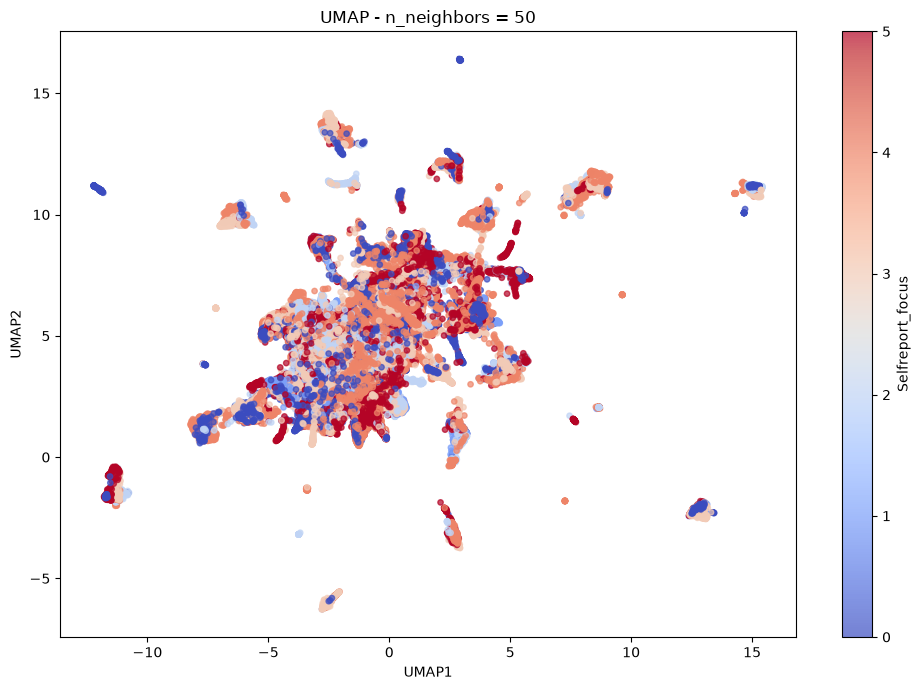

In [23]:
# =====================================================
# 5. UMAP - Comparación de n_neighbors
# =====================================================

import umap
import matplotlib.pyplot as plt
import pandas as pd

#for n in (2, 5, 10, 20, 50, 100, 200):

    # Crear y entrenar UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=50,
    min_dist=0.1,
    metric='euclidean',
    random_state=67
)

X_umap = reducer.fit_transform(X_scaled)

# Crear DataFrame
umap_df = pd.DataFrame(
    X_umap,
    columns=['UMAP1', 'UMAP2'],
    index=df.index
)

umap_df[['Selfreport_focus', 'Task_Num','Task_Type']] = y_focus
# Visualizar resultados
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    umap_df['UMAP1'],
    umap_df['UMAP2'],
    c=umap_df['Selfreport_focus'],
    cmap='coolwarm',
    alpha=0.7,
    s=15
)

plt.colorbar(scatter, label='Selfreport_focus')
plt.title(f'UMAP - n_neighbors = {50}')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.tight_layout()
plt.show()

In [24]:

# =====================================================
# 6. t-SNE
# =====================================================

# Perplexity must be smaller than the number of observations
perplexity = min(30, len(X_scaled) - 1)

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    learning_rate='auto',
    max_iter=1000,
    init='pca',
    random_state=67
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=df.index
)

tsne_df[['Selfreport_focus', 'Task_Num','Task_Type']] = y_focus



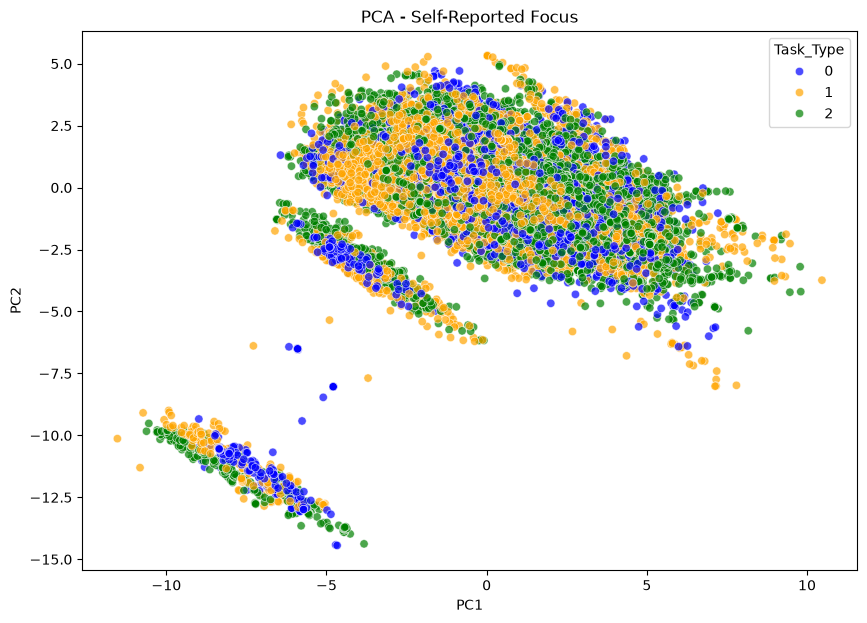

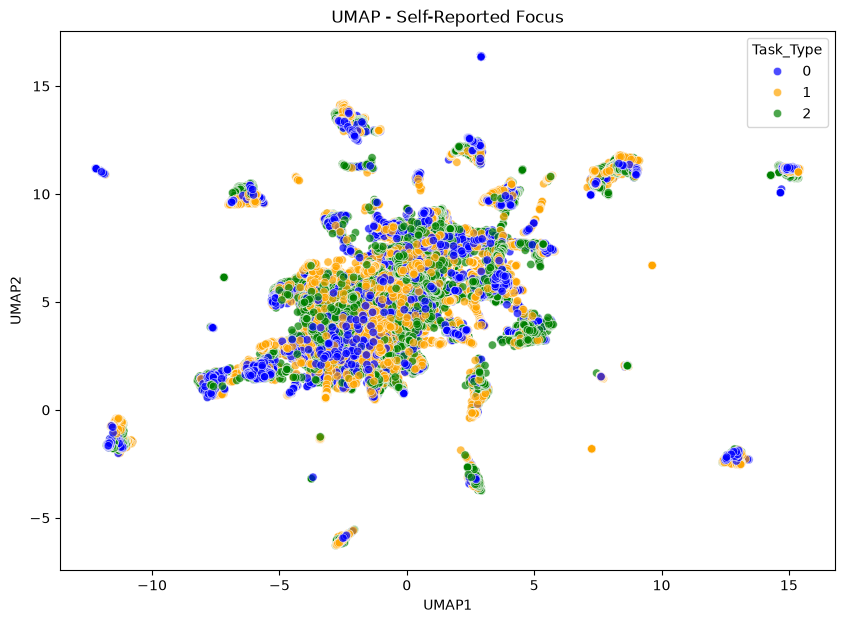

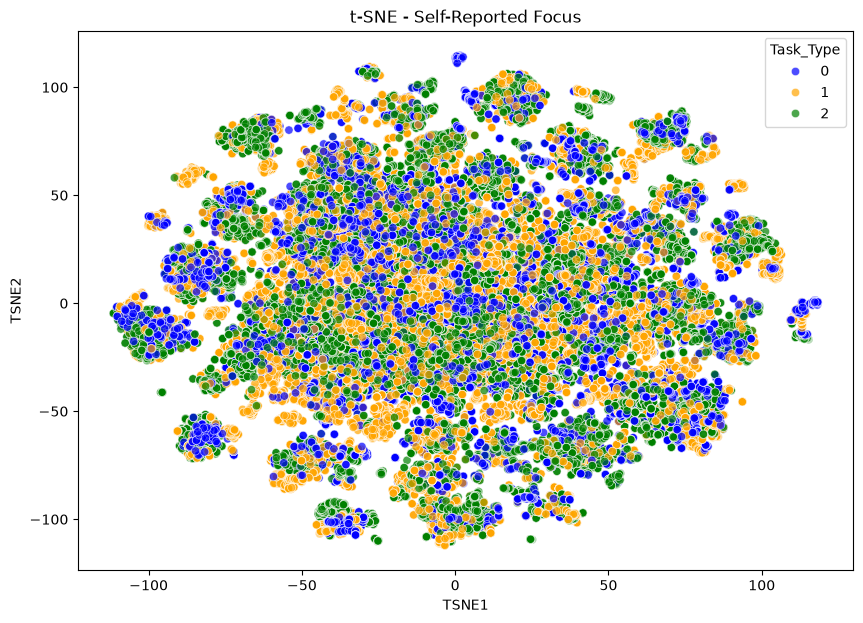

In [33]:

# =====================================================
# 7. VISUALIZATION
# =====================================================
task_palette = {
    0: 'blue',
    1: 'orange',
    2: 'green'
}
# PCA
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Task_Type', #'Selfreport_focus',
    palette=task_palette,
    alpha=0.7
)

plt.title('PCA - Self-Reported Focus')
plt.show()


# UMAP
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=umap_df,
    x='UMAP1',
    y='UMAP2',
    hue='Task_Type', #'Selfreport_focus',
    palette=task_palette,
    alpha=0.7
)

plt.title('UMAP - Self-Reported Focus')
plt.show()


# t-SNE
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x='TSNE1',
    y='TSNE2',
    hue='Task_Type', #'Selfreport_focus',
    palette=task_palette,
    alpha=0.7
)

plt.title('t-SNE - Self-Reported Focus')
plt.show()

division of the sections
https://www.mdpi.com/2306-5729/10/7/103 in that paper you can read a description of each section, we divided into similar sections to try and find groups with in groups

2.1 Initial meditation
8.1 Final meditation



3.1 Mathematics task
5.1 Concentration video 1
5.2 Concentration video 1 task
5.3 Concentration video 2
5.4 Concentration video 2 task


4.1 Auditory stimulation
6.1 Emotional video
7.1 Writing task instructions
7.2 Writing task 1
7.3 Writing task 2
7.4 Writing task 3


9.1 User experience survey
1.1 Participant Profile
3.2 Mathematics task self-report
5.5 Concentration videos self-report
7.5 Writing task self-report
6.2 Emotional video self-report
8.2 Final meditation self-report
4.2 Auditory stimulation self-report
2.2 Initial meditation self-report



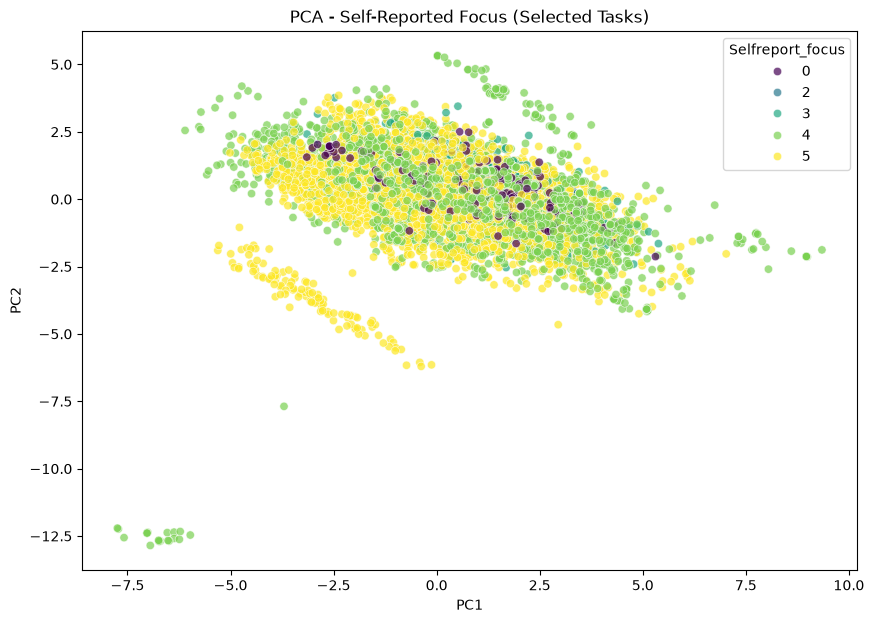

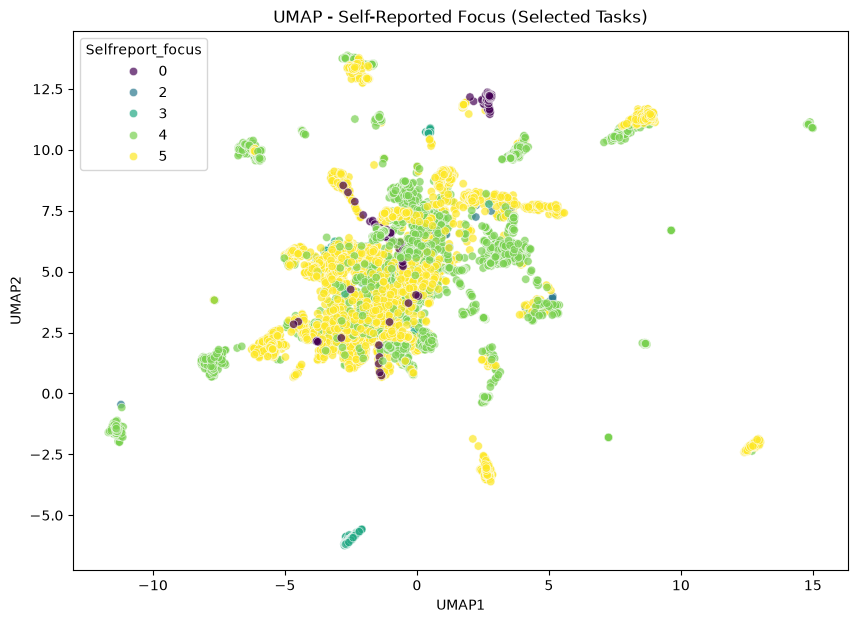

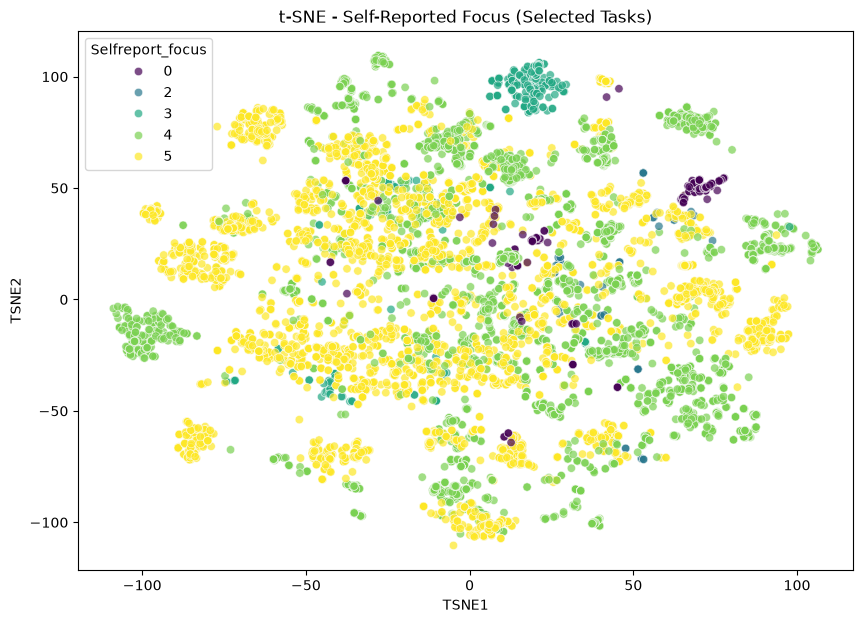

In [32]:
all_tasks = [
    [2.1, 8.1,], # meditations
    [3.1, 5.1, 5.2, 5.3, 5.4,], # mathematics
    [4.1, 6.1, 7.1, 7.2, 7.3, 7.4,], # Emotional
    [9.1, 1.1, 3.2, 5.5, 7.5, 6.2, 8.2, 4.2, 2.2] # Surveys
] 
selected_tasks = all_tasks[1]

pca_filtered = pca_df[pca_df['Task_Num'].isin(selected_tasks)]
umap_filtered = umap_df[umap_df['Task_Num'].isin(selected_tasks)]
tsne_filtered = tsne_df[tsne_df['Task_Num'].isin(selected_tasks)]

# PCA
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_filtered,
    x='PC1',
    y='PC2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('PCA - Self-Reported Focus (Selected Tasks)')
plt.show()


# UMAP
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=umap_filtered,
    x='UMAP1',
    y='UMAP2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('UMAP - Self-Reported Focus (Selected Tasks)')
plt.show()


# t-SNE
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_filtered,
    x='TSNE1',
    y='TSNE2',
    hue='Selfreport_focus',
    palette='viridis',
    alpha=0.7
)

plt.title('t-SNE - Self-Reported Focus (Selected Tasks)')
plt.show()